In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd

from src import eda, evaluate
from src.config import FEATURE_IMPORTANCE_PATH, PREDICTIONS_PATH, SUMMARY_PATH


# Klasyfikacja ADHD na podstawie EEG - analiza

Ten notebook nie trenuje niczego od nowa. Wczytuje wyniki policzone wcześniej przez
`python -m src.train` i `python -m src.evaluate` (pliki w `results/`) i pokazuje je przez
te same funkcje, których używają skrypty w `src/`. Sekcja EDA liczy statystyki opisowe
bezpośrednio z surowych danych - to nie jest trening modelu, tylko podgląd sygnału.

Nie jestem specjalistą od EEG ani od ADHD - obserwacje poniżej są uczciwym opisem
tego, co wyszło z danych, nie interpretacją kliniczną.


## 1. Dane - podstawowe statystyki

Class
ADHD       61
Control    60
Name: count, dtype: int64

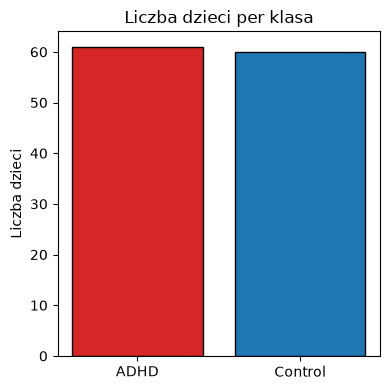

In [2]:
df = eda.load_raw()
fig, counts = eda.class_distribution(df)
counts


61 dzieci ADHD, 60 Control - klasy są praktycznie zbalansowane.

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
ADHD,61.0,154.593878,58.136960,72.546875,111.750000,143.664062,185.007812,337.906250
Control,60.0,124.910677,29.906607,62.367188,104.607422,122.101562,139.101562,203.007812


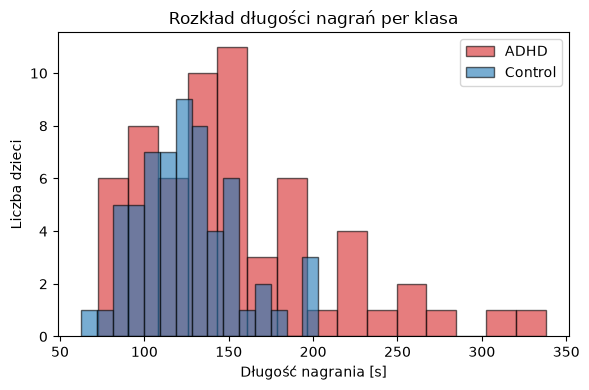

In [3]:
fig, lengths = eda.recording_length_distribution(df)
lengths.groupby("Class")["duration_sec"].describe()


Nagrania ADHD są średnio dłuższe niż Control (ok. 155s vs 125s) i mają większy rozrzut
długości. Ma to znaczenie przy cięciu na okna: dzieci z ADHD dają więcej okien, dlatego
w treningu ważę okna wagą 1 / liczba okien dziecka, żeby dłuższe nagrania nie miały
większego wpływu na uczenie modelu.

## 2. Surowy sygnał i widmo mocy

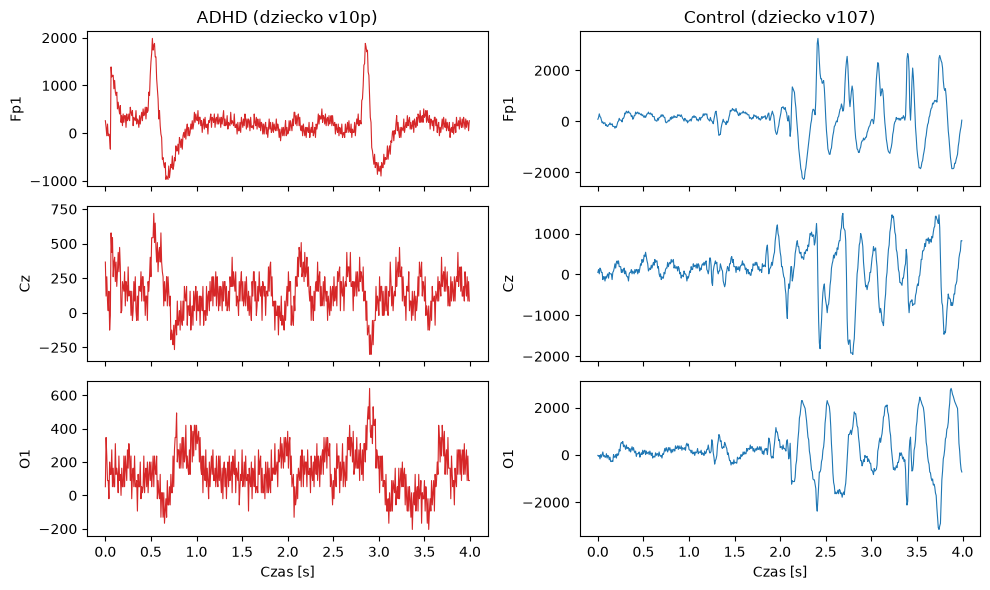

In [4]:
eda.plot_raw_signal_examples(df);


To tylko wizualny punkt odniesienia przed przejściem do cech częstotliwościowych.

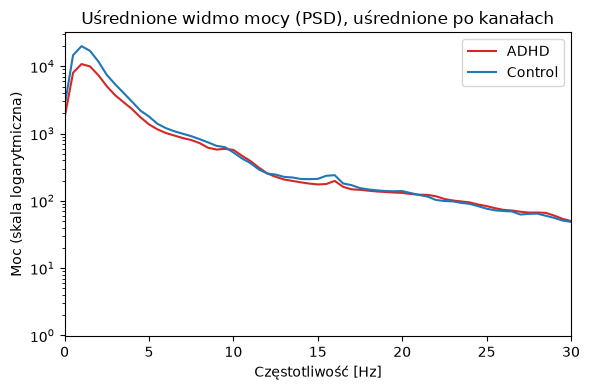

In [5]:
records = eda.compute_psd_per_child(df)
freqs, psd_by_class = eda.average_psd_by_class(records)
eda.plot_average_psd(freqs, psd_by_class);


## 3. Stosunek theta/beta

Stosunek theta/beta dodałem jako dodatkową cechę, bo doczytałem, że często pojawia się
w kontekście EEG i ADHD. Nie jest to podpowiedź wprost z treści zadania.

,ADHD,Control
Fp1,3.235,3.285
Fp2,2.840,2.648
F3,3.056,3.752
F4,2.477,2.792
C3,3.401,4.249
C4,2.984,3.141
P3,2.645,2.521
P4,2.656,3.042
O1,1.644,2.449
O2,1.352,1.817


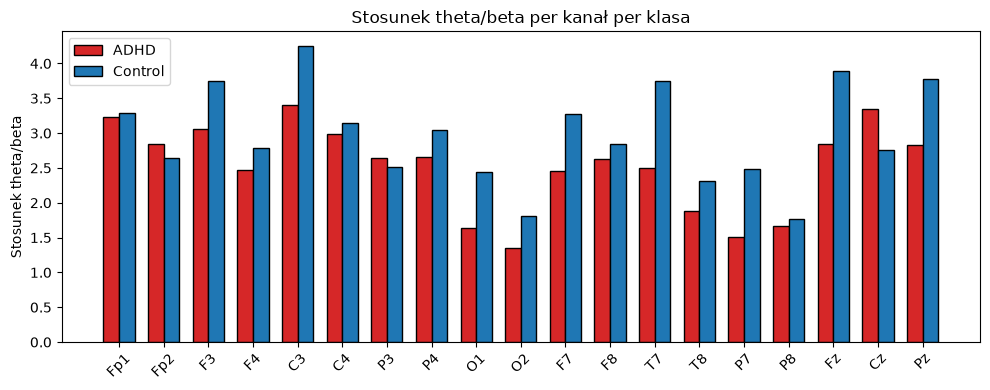

In [6]:
ratios = eda.theta_beta_ratio_per_channel(freqs, psd_by_class)
eda.plot_theta_beta_ratio(ratios)
pd.DataFrame(ratios, index=eda.CHANNELS).round(3)


W większości kanałów theta/beta wyszło niższe dla ADHD niż dla Control - odwrotnie
niż kierunek najczęściej opisywany w literaturze dla EEG spoczynkowego. Nie próbuję
tego tłumaczyć, to obserwacja z danych.

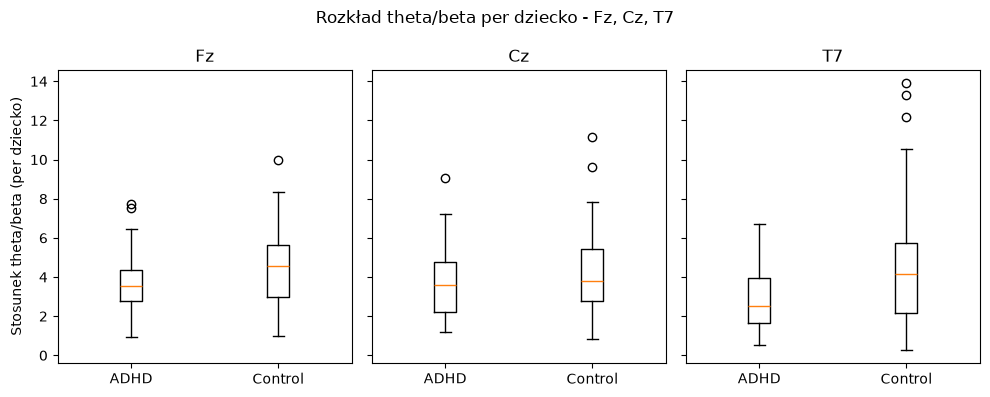

In [7]:
per_child_ratio = eda.theta_beta_ratio_per_child(records)
eda.plot_theta_beta_boxplot_per_child(per_child_ratio);


Boxplot pokazuje, że to przesunięcie całej grupy, a nie efekt kilku odstających dzieci.

## 4. Wyniki modeli (bez ponownego treningu)

Poniżej wczytuję predykcje out-of-fold i metryki policzone wcześniej przez `train.py`
i `evaluate.py`.

In [8]:
predictions = pd.read_csv(PREDICTIONS_PATH)
summary = pd.read_csv(SUMMARY_PATH)
summary.round(3)


,variant,model,balanced_accuracy_mean,balanced_accuracy_std,recall_mean,recall_std,precision_mean,precision_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,whole_recording,logreg,0.571,0.051,0.608,0.082,0.577,0.061,0.587,0.037,0.645,0.082
1,whole_recording,random_forest,0.660,0.095,0.737,0.110,0.650,0.086,0.686,0.081,0.737,0.056
2,windows,logreg,0.653,0.049,0.722,0.040,0.645,0.067,0.678,0.023,0.681,0.067
3,windows,random_forest,0.677,0.058,0.887,0.088,0.631,0.049,0.735,0.043,0.712,0.028


Wszystkie 4 kombinacje (2 warianty danych x 2 modele) mają balanced accuracy i ROC AUC
wyraźnie powyżej 0.5, czyli lepiej niż przypadek. Odchylenia standardowe po 5 foldach
(0.05-0.10) są jednak na tyle duże względem różnic między kombinacjami, że nie wskazuję
jednej jako zdecydowanie najlepszej.

In [9]:
best_variant, best_model = evaluate.pick_best(summary)
print(f"Najlepsza kombinacja wg balanced accuracy: {best_variant} / {best_model}")

best_by_auc = summary.loc[summary["roc_auc_mean"].idxmax()]
print(f"Najlepsza kombinacja wg ROC AUC: {best_by_auc['variant']} / {best_by_auc['model']}")


Najlepsza kombinacja wg balanced accuracy: windows / random_forest
Najlepsza kombinacja wg ROC AUC: whole_recording / random_forest


Te dwie metryki wskazują różne kombinacje jako najlepsze - to kolejny sygnał, że żadna
kombinacja nie ma wyraźnej przewagi.

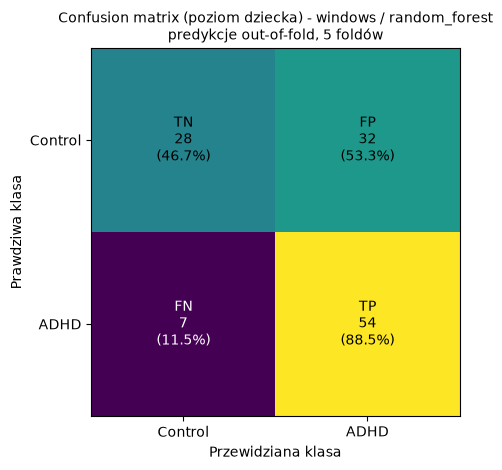

In [10]:
evaluate.plot_confusion_matrix_for(predictions, best_variant, best_model);


Macierz pomyłek dla kombinacji wybranej po balanced accuracy pokazuje wyraźne przechylenie
w stronę klasy ADHD: recall dla ADHD jest dużo wyższy niż precision, model częściej
"strzela" ADHD. Zostawiłem próg na domyślnym 0.5 - dobór progu wymagałby osobnego
zbioru walidacyjnego, a ustawienie go na podstawie tych wyników byłoby dopasowaniem
do danych testowych.

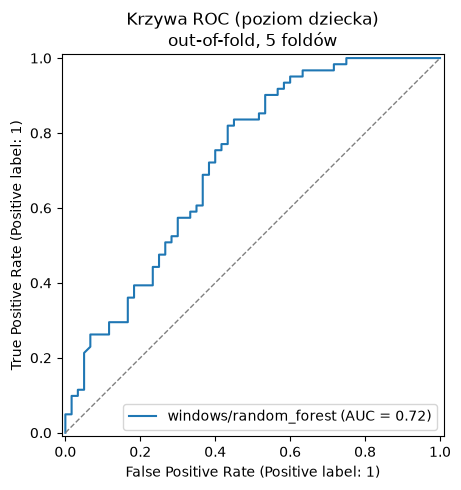

In [11]:
evaluate.plot_roc_curve_for(predictions, best_variant, best_model);


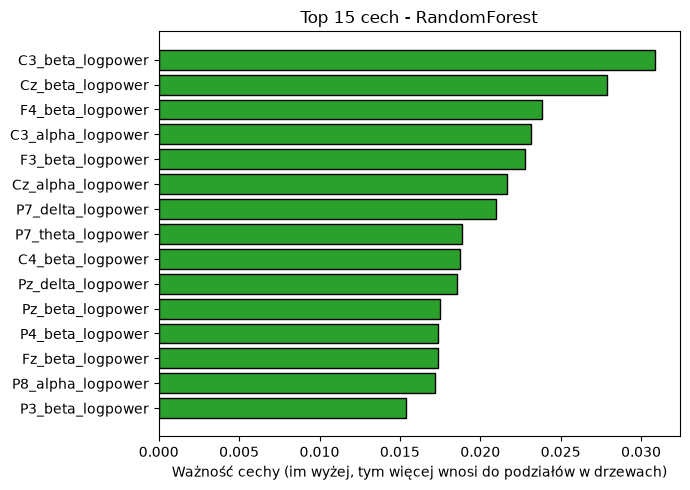

In [12]:
importance = pd.read_csv(FEATURE_IMPORTANCE_PATH)
evaluate.plot_feature_importance(importance);


Najważniejsze cechy dla RandomForest to w większości moc w paśmie beta z różnych kanałów.
Nie interpretuję dalej, które konkretnie kanały "powinny" być najważniejsze.

## 5. Wnioski

- Wszystkie 4 sprawdzone kombinacje (2 warianty danych x 2 modele, bez strojenia
  hiperparametrów) biją poziom losowy - balanced accuracy i ROC AUC powyżej 0.5.
- Różnice między kombinacjami mieszczą się w rozrzucie wyników między foldami
  (std rzędu 0.05-0.10), więc nie wskazuję jednej konfiguracji jako wyraźnie najlepszej.
- Balanced accuracy wskazuje jako najlepszą kombinację windows/RandomForest, a ROC AUC -
  whole_recording/RandomForest. Różne metryki wskazują różnych "zwycięzców" - to kolejny
  sygnał, że żadna kombinacja nie ma wyraźnej przewagi.
- Najlepszy wg balanced accuracy model (windows/RandomForest) jest przechylony w stronę
  przewidywania ADHD: recall znacznie wyższy niż precision. Zostawiłem próg na domyślnym
  0.5 - dobór progu wymagałby osobnego zbioru walidacyjnego, a ustawienie go na podstawie
  tych wyników byłoby dopasowaniem do danych testowych.
- Stosunek theta/beta dodałem jako dodatkową cechę, bo doczytałem, że często pojawia się
  w kontekście EEG i ADHD - nie wynikała wprost z treści zadania. Wyszła w moich danych
  odwrotnie niż kierunek typowo opisywany w literaturze. Nie próbuję tego tłumaczyć,
  nie jestem specjalistą od EEG, żeby oceniać przyczyny.
- Ograniczenia: mały zbiór (121 dzieci), brak strojenia hiperparametrów, brak
  zaawansowanego przetwarzania sygnału (filtrowanie, usuwanie artefaktów).
